# Sequence analysis notebook
This notebook analyses thermal sequences using Konrad's toolkit.

In [1]:
import pulse_method.toolbox_pulse as therm
import matplotlib.pyplot as plt
import torch
import os
import numpy as np

In [2]:
# check for GPU availability
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
analyzer = therm.thermograms(height=512, width=640)

In [4]:
sequence_dir = "/home/burguea/Data1/thermograms/"
# list all folders in sequence dir and get paths to calibrated subfolders
calibrated_paths = []
for folder in os.listdir(sequence_dir):
    folder_path = os.path.join(sequence_dir, folder)
    if os.path.isdir(folder_path):
        calibrated_path = os.path.join(folder_path, "calibrated")
        if os.path.exists(calibrated_path):
            calibrated_paths.append(calibrated_path)

# sort the paths for consistent ordering
calibrated_paths.sort()

# print available sequences
print("Available thermographic sequences:")
for i, path in enumerate(calibrated_paths):
    folder_name = os.path.basename(os.path.dirname(path))
    print(f"{i}: {folder_name} -> {path}")

Available thermographic sequences:
0: d1-1lamp-15s -> /home/burguea/Data1/thermograms/d1-1lamp-15s/calibrated
1: d1-2lamps-15s -> /home/burguea/Data1/thermograms/d1-2lamps-15s/calibrated
2: d1-3lamps-15s -> /home/burguea/Data1/thermograms/d1-3lamps-15s/calibrated
3: d1-4lamps-15s -> /home/burguea/Data1/thermograms/d1-4lamps-15s/calibrated
4: d130deg -> /home/burguea/Data1/thermograms/d130deg/calibrated
5: d1_20s_heating_konrad -> /home/burguea/Data1/thermograms/d1_20s_heating_konrad/calibrated
6: d1backside -> /home/burguea/Data1/thermograms/d1backside/calibrated
7: d1cold_30sheat -> /home/burguea/Data1/thermograms/d1cold_30sheat/calibrated
8: d1cold_slowheat -> /home/burguea/Data1/thermograms/d1cold_slowheat/calibrated
9: d1freeze -> /home/burguea/Data1/thermograms/d1freeze/calibrated
10: d1oven45 -> /home/burguea/Data1/thermograms/d1oven45/calibrated
11: d2-15s -> /home/burguea/Data1/thermograms/d2-15s/calibrated
12: d2-20s -> /home/burguea/Data1/thermograms/d2-20s/calibrated
13: d2-

In [5]:
selection = 10
print(f"selected sequence {selection,calibrated_paths[selection]}")
# data = analyzer.loadfrombinfiles("/home/burguea/Data1/thermograms/d2oven45/temperature",dtype='float32')
data = analyzer.loadfrombinfiles(calibrated_paths[selection])
print("sequence length: {}".format(data.shape[0]))

selected sequence (10, '/home/burguea/Data1/thermograms/d1oven45/calibrated')
sequence length: 9000


In [6]:
# plt.imsave(arr=data[time_start, :, :],fname="initial_frame.png", cmap='inferno')

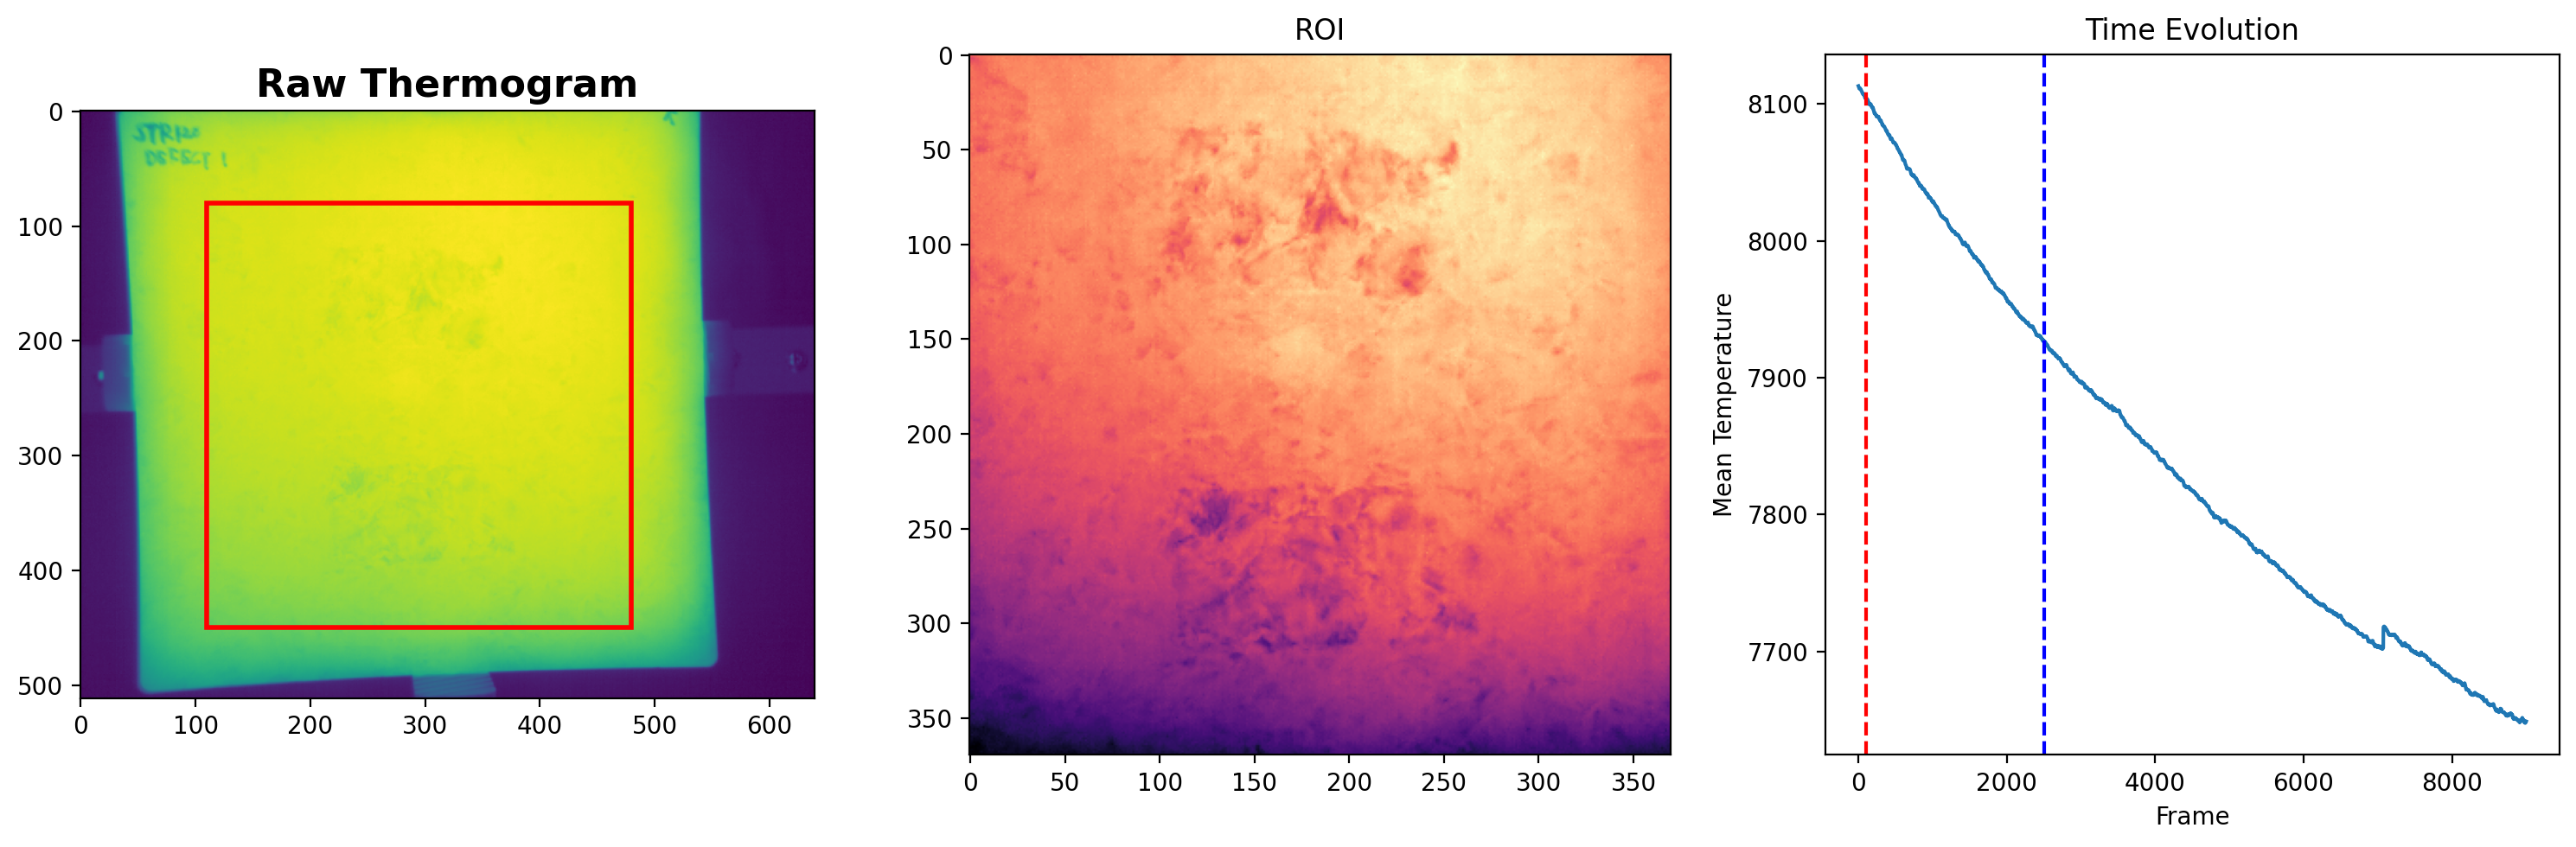

In [17]:
from matplotlib.patches import Rectangle

# plot one frame of the data to determine the ROI and the time evolution of the pixel values (temperature)
roi_left = 110
roi_right = 480
roi_top = 80
roi_bottom = 450
time_start = 100
time_end = 2500
plt.figure(figsize=(15, 5),dpi=200)
plt.subplot(1, 3, 1)
plt.imshow(data[time_start, :, :])
# plt.title("Frame {}".format(time_start))
plt.title('Raw Thermogram', weight='bold', size=16)
# Add rectangle overlay for ROI
rect = Rectangle(
    (roi_left, roi_top),
    roi_right - roi_left,
    roi_bottom - roi_top,
    linewidth=2,
    edgecolor="red",
    facecolor="none",
)
plt.gca().add_patch(rect)
plt.subplot(1, 3, 2)
plt.imshow(data[time_start, roi_top:roi_bottom, roi_left:roi_right],cmap='magma')
plt.title("ROI")
plt.subplot(1, 3, 3)
plt.plot(data[:, roi_top:roi_bottom, roi_left:roi_right].mean(axis=(1, 2)))
plt.title("Time Evolution")
plt.axvline(x=time_start, color="r", linestyle="--")
plt.axvline(x=time_end, color="b", linestyle="--")
plt.xlabel("Frame")
plt.ylabel("Mean Temperature")

plt.tight_layout()
plt.show()

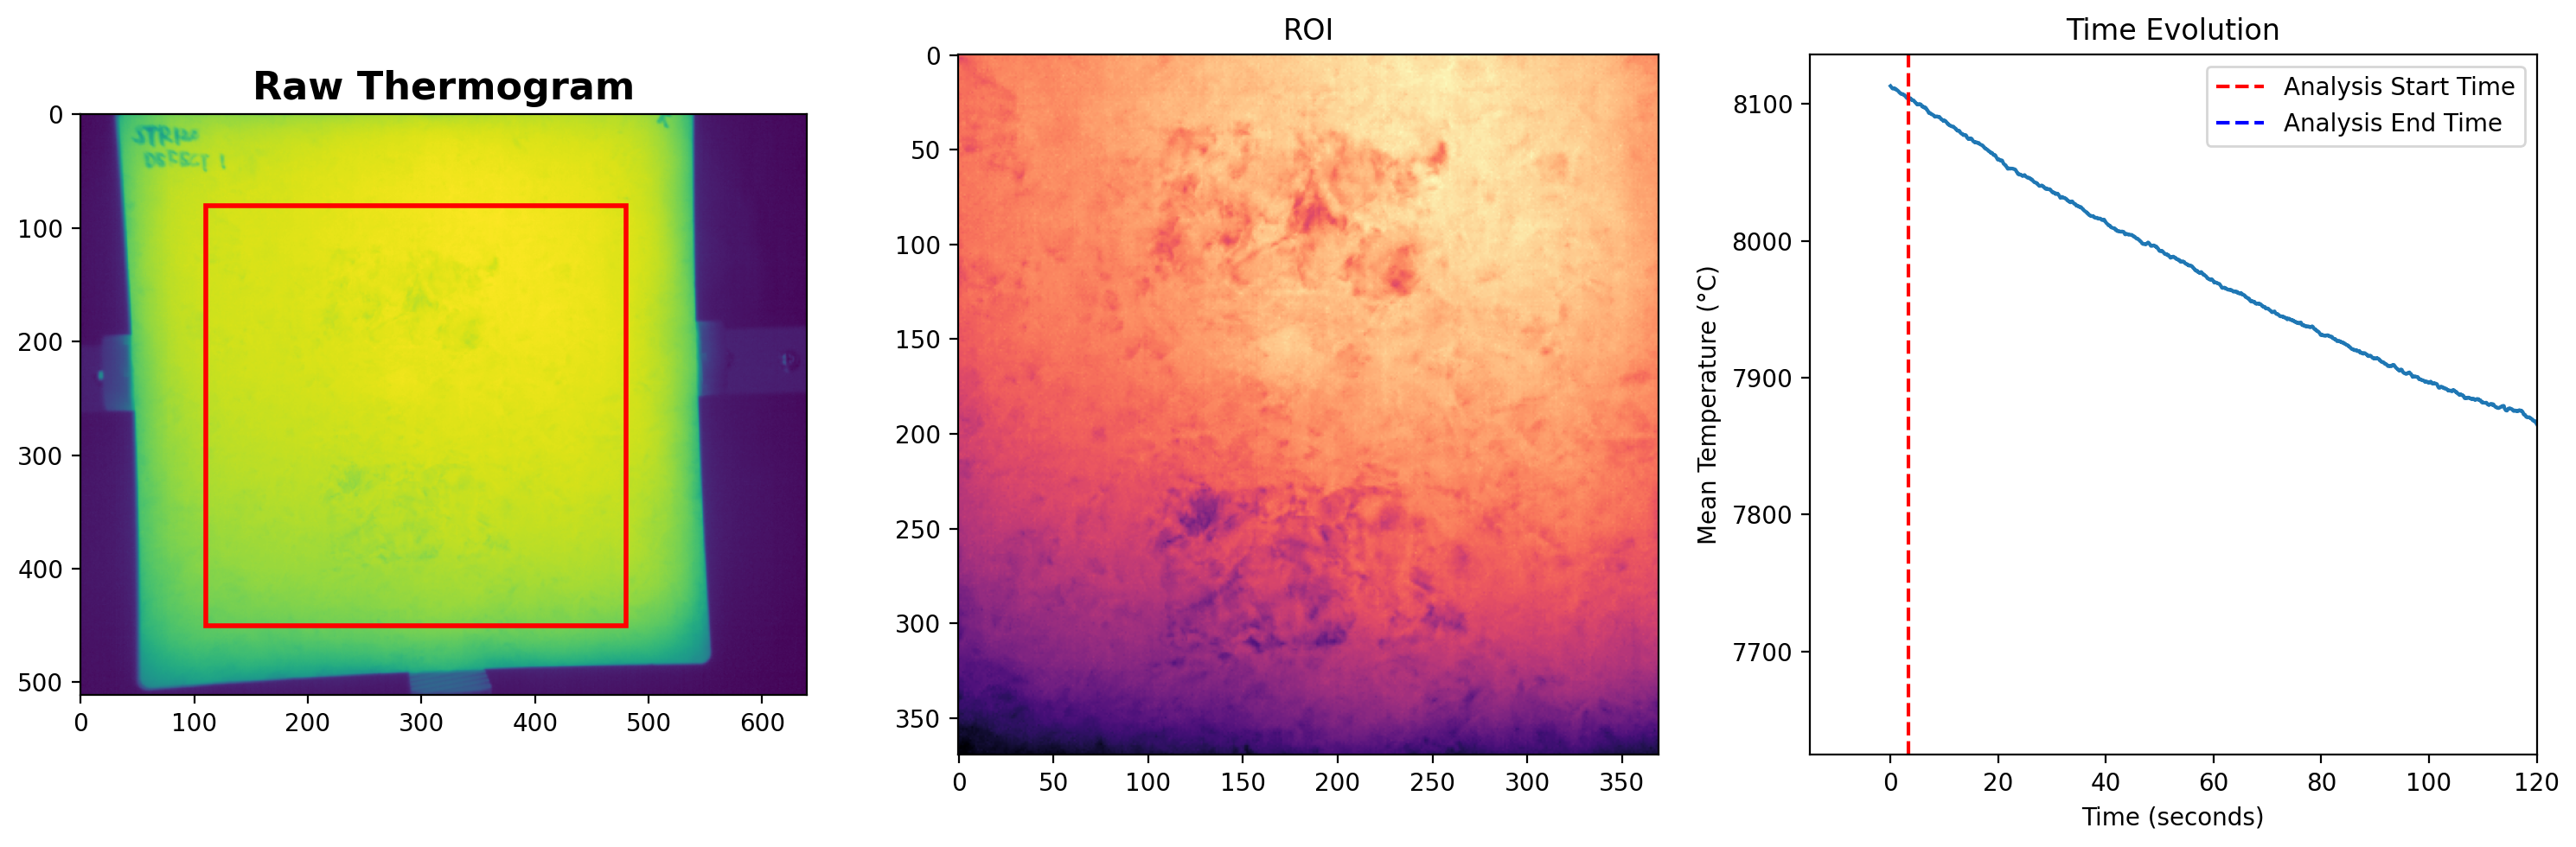

In [ ]:
from matplotlib.patches import Rectangle

# plot one frame of the data to determine the ROI and the time evolution of the pixel values (temperature)
roi_left = 110
roi_right = 480
roi_top = 80
roi_bottom = 450
time_start = 100
time_end = 6000
plt.figure(figsize=(15, 5), dpi=200)
plt.subplot(1, 3, 1)
plt.imshow(data[time_start, :, :])
# plt.title("Frame {}".format(time_start))
plt.title("Raw Thermogram", weight="bold", size=16)
# Add rectangle overlay for ROI
rect = Rectangle(
    (roi_left, roi_top),
    roi_right - roi_left,
    roi_bottom - roi_top,
    linewidth=2,
    edgecolor="red",
    facecolor="none",
)
plt.gca().add_patch(rect)
plt.subplot(1, 3, 2)
plt.imshow(data[time_start, roi_top:roi_bottom, roi_left:roi_right], cmap="magma")
plt.title("ROI")
plt.subplot(1, 3, 3)
plt.plot(np.arange(len(data))/30,data[:, roi_top:roi_bottom, roi_left:roi_right].mean(axis=(1, 2)))
plt.title("Time Evolution")
plt.axvline(x=time_start/30, color="r", linestyle="--", label="Analysis Start Time")
plt.axvline(x=time_end/30, color="b", linestyle="--", label="Analysis End Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Mean Temperature (°C)")
plt.xlim(right=120)
plt.legend()
plt.tight_layout()
plt.show()
# np.save("../data/real/d1_cooldown.npy", data[time_start, roi_top:roi_bottom, roi_left:roi_right])

In [18]:
# Reduce the data to the region of interest (ROI) in space and time
data_roi = data[time_start:time_end, roi_top:roi_bottom, roi_left:roi_right]

# Get defect detection algorithm output
HOS_matrix = analyzer.HOS_torch(data_roi)
phasegram, magnitude = analyzer.PPT_torch(data_roi, mode_num=5)
coefficients, _, _ = analyzer.TSR_torch(data_roi, polynomial_order=2)

# Generate defect maps overview
skewness, fifth_moment = HOS_matrix[0, :, :].numpy(), HOS_matrix[2, :, :].numpy()
defect_magnitude = magnitude[2].numpy()
defect_phase = phasegram[2].numpy()
defect_poly = coefficients[2].numpy()

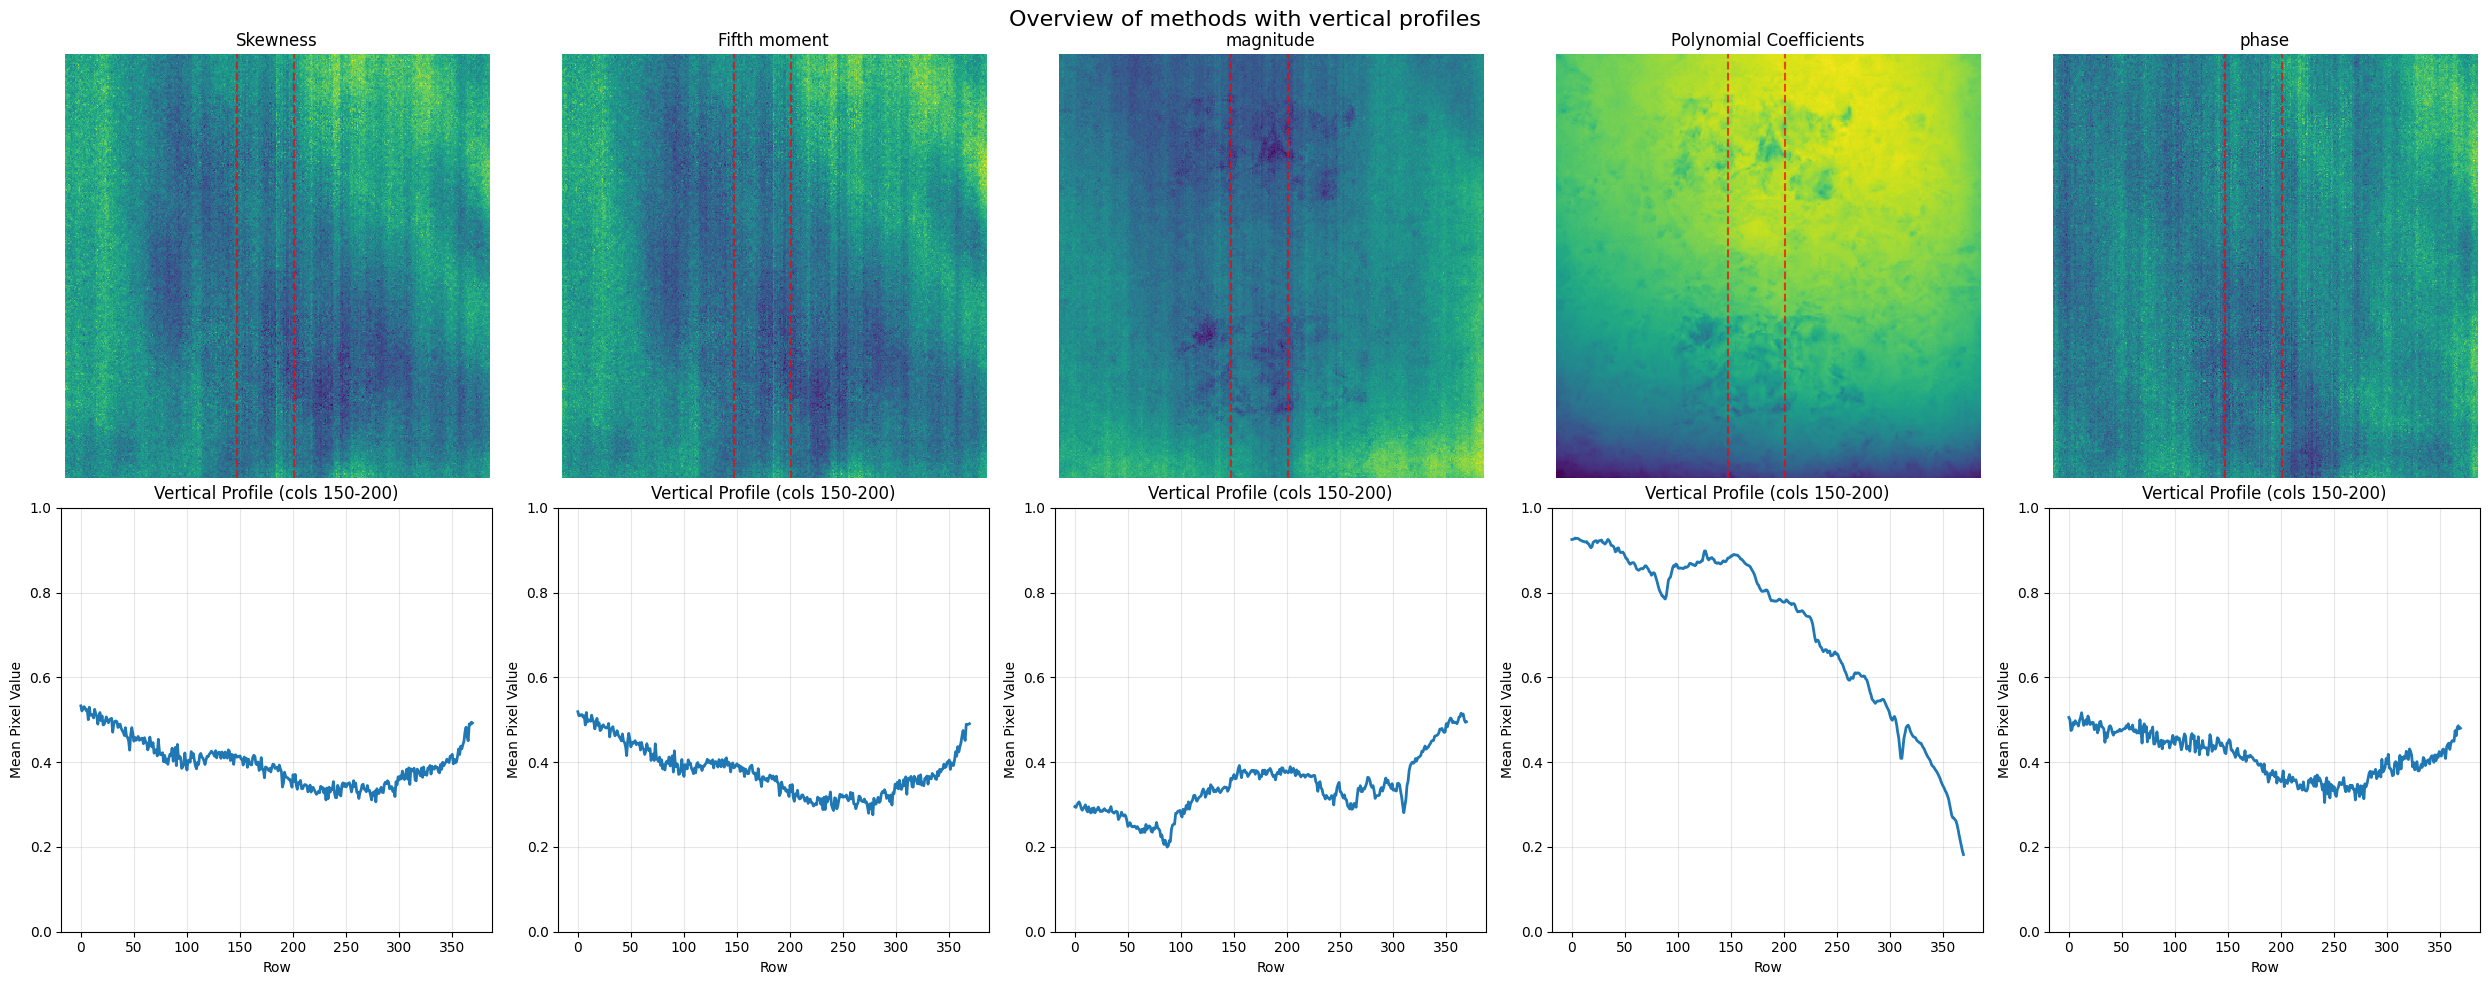

In [19]:
# Plot all basic defect maps
raw_defect_maps = [
    skewness,
    fifth_moment,
    defect_magnitude,
    defect_poly,
    defect_phase,
]
titles = ["Skewness", "Fifth moment", "magnitude", "Polynomial Coefficients", "phase"]


# normalize all defect maps
def normalize_map(defect_map):
    min_val = defect_map.min()
    max_val = defect_map.max()
    if max_val > min_val:
        return (defect_map - min_val) / (max_val - min_val)
    return defect_map


normalized_defect_maps = [normalize_map(dm) for dm in raw_defect_maps]

# Define vertical strip limits for profile analysis
vertical_strip_lims = (150, 200)

# Create figure with 2 rows: top for images, bottom for vertical profiles
fig, axs = plt.subplots(2, 5, figsize=(25, 10))

# Top row: defect maps
for i, (defect_map, title) in enumerate(zip(normalized_defect_maps, titles)):
    axs[0, i].imshow(defect_map, cmap="viridis", interpolation="nearest")
    axs[0, i].set_title(title)
    axs[0, i].axis("off")

    # Add vertical lines to show the strip region
    axs[0, i].axvline(x=vertical_strip_lims[0], color="red", linestyle="--", alpha=0.7)
    axs[0, i].axvline(x=vertical_strip_lims[1], color="red", linestyle="--", alpha=0.7)

# Bottom row: vertical section profiles
for i, (defect_map, title) in enumerate(zip(normalized_defect_maps, titles)):
    # Calculate mean over the vertical strip
    vertical_profile = defect_map[
        :, vertical_strip_lims[0] : vertical_strip_lims[1]
    ].mean(axis=1)

    axs[1, i].plot(vertical_profile, linewidth=2)
    axs[1, i].set_ylim(0, 1)
    axs[1, i].set_title(
        "Vertical Profile (cols {}-{})".format(
            vertical_strip_lims[0], vertical_strip_lims[1]
        )
    )
    axs[1, i].set_xlabel("Row")
    axs[1, i].set_ylabel("Mean Pixel Value")
    axs[1, i].grid(True, alpha=0.3)

plt.suptitle("Overview of methods with vertical profiles", fontsize=16)
plt.tight_layout()
plt.show()

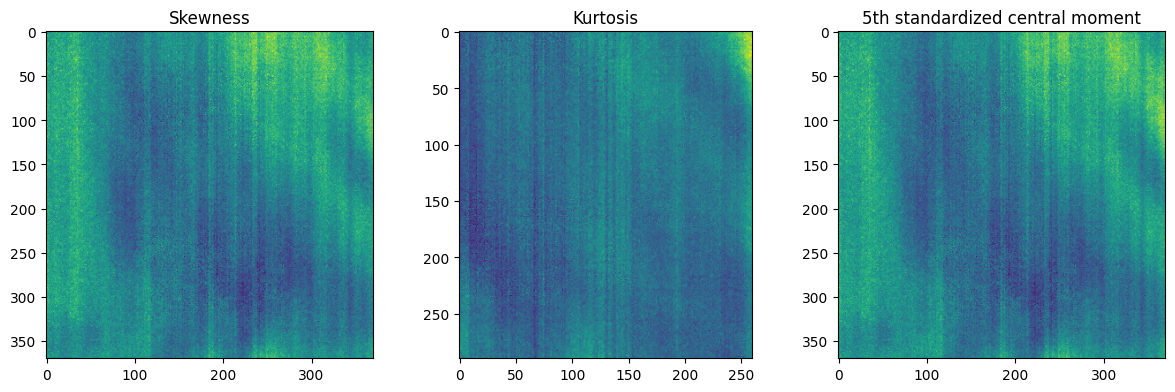

In [20]:
# plot the three entries of the HOS matrix
plt.figure(figsize=(12, 4), dpi=100)
plt.subplot(1, 3, 1)
plt.imshow(HOS_matrix[0, :, :])
plt.title("Skewness")
plt.subplot(1, 3, 2)
plt.imshow(HOS_matrix[1, roi_top:roi_bottom, roi_left:roi_right])
plt.title("Kurtosis")
plt.subplot(1, 3, 3)
plt.imshow(HOS_matrix[2, :, :])
plt.title("5th standardized central moment")
plt.tight_layout()
plt.show()

to_save = (HOS_matrix[2]).numpy()
# np.save("../data/real/pristine.npy", to_save)

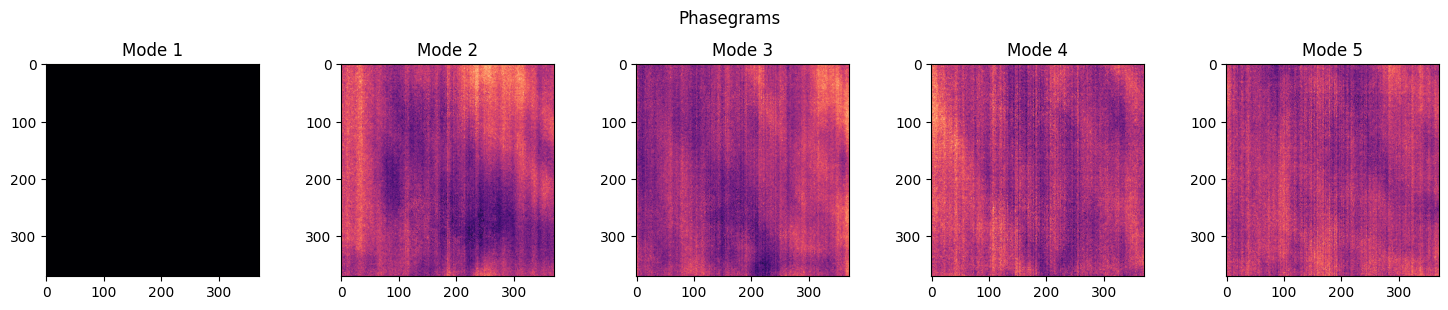

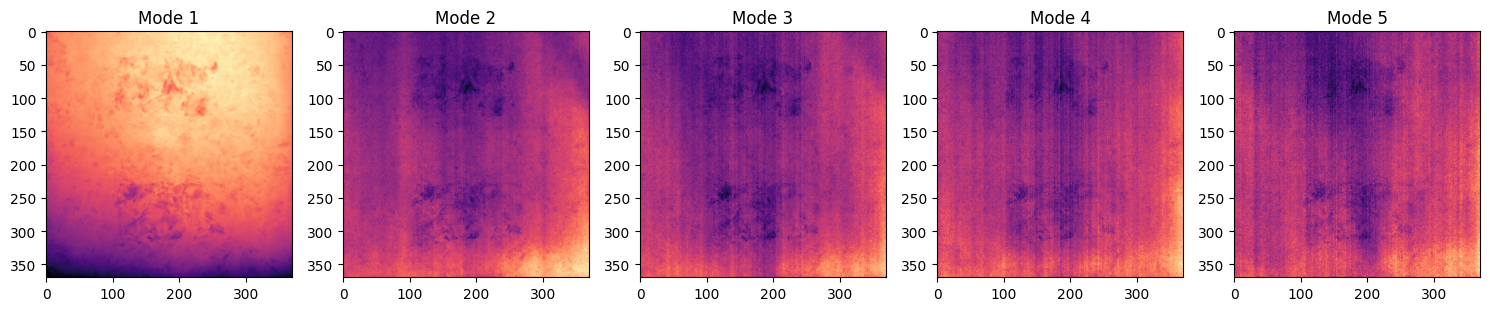

In [31]:
phasegram, magnitude = analyzer.PPT_torch(data_roi, mode_num=5)
# Plot all entries of the phasegram
plt.figure(figsize=(15, 8))
for i in range(phasegram.shape[0]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(phasegram[i, :, :], cmap="magma")
    plt.title(f"Mode {i + 1}")
plt.suptitle("Phasegrams")
plt.tight_layout()

plt.show()
# Plot all entries of the magnitude
plt.figure(figsize=(15, 10))
for i in range(magnitude.shape[0]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(magnitude[i, :, :], cmap="magma")
    plt.title(f"Mode {i + 1}")
plt.tight_layout()
plt.show()


to_save = (magnitude[2]).numpy()
np.save("../data/real/d1_cooldownb.npy", to_save)

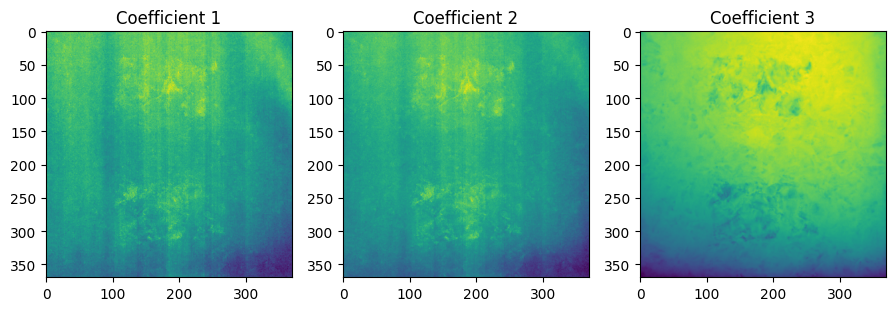

r2mean tensor(0.9656)


In [33]:
coefficients, reconstruction, r2map = analyzer.TSR_torch(data_roi, polynomial_order=2)
# Plot the coefficients
plt.figure(figsize=(15, 10))
for i in range(coefficients.shape[0]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(coefficients[i, :, :])
    plt.title(f"Coefficient {i + 1}")
plt.tight_layout()
plt.show()
print("r2mean", r2map.mean())

# save second coefficient as a numpy array
np.save('../data/real/d1_cooldownc.npy', coefficients[1].cpu().numpy())

In [23]:
# Dynamic mode decomposition
modes, eigenvalues = analyzer.DMD_torch(data_roi, truncation=10)

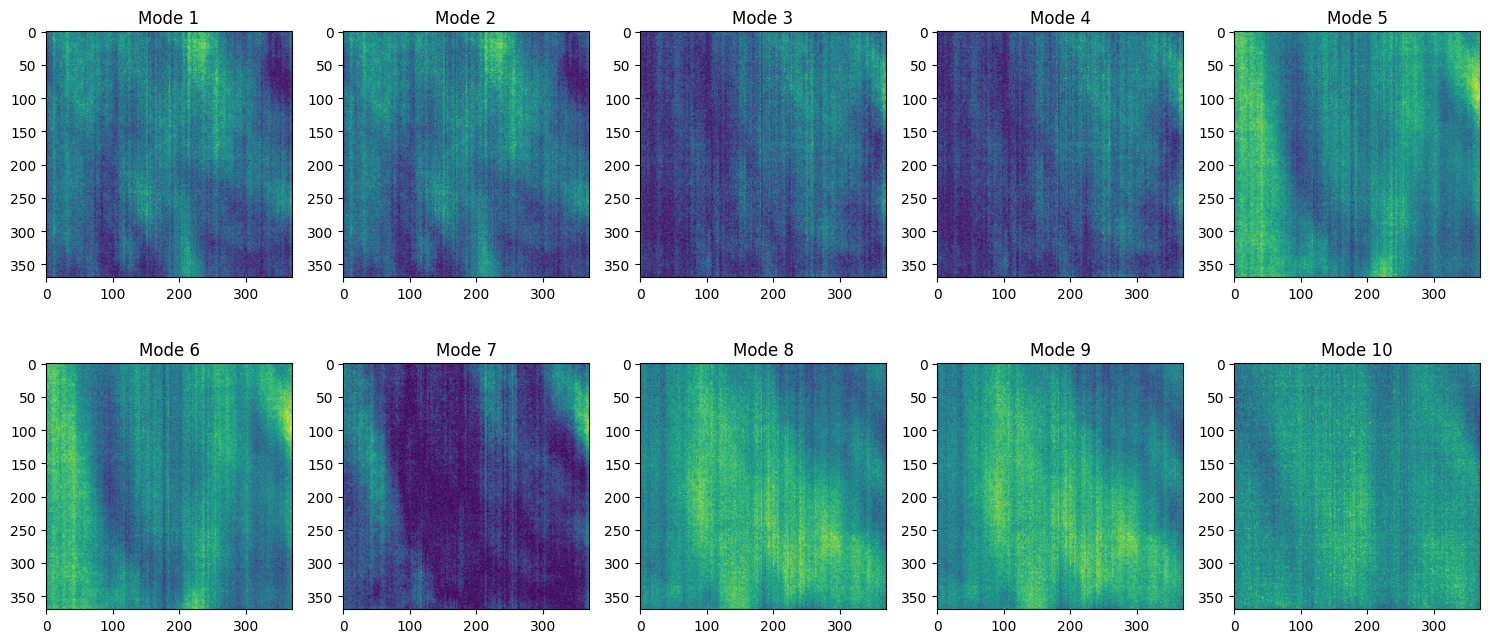

In [24]:
# Plot the modes
plt.figure(figsize=(15, 10))
for i in range(modes.shape[0]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(torch.abs(modes[i, :, :]), cmap="viridis")
    plt.title(f"Mode {i + 1}")
plt.tight_layout()
plt.show()
# np.save('../data/real/defect_map.npy', torch.abs(modes[3]).cpu().numpy())